In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


### How the alpha abundance changes for a given star

Previously, I had set the [alpha/Fe] abundance to 0.4 dex for all stars in Korg. This is assuming a lot of things though, so we'll instead set [alpha/Fe] to be that from the derived abundances. 

I'll test for star **ra_1752-4300_s269**, which has the lowest measured [alpha/Fe] value of 0.14 dex.

In [2]:
# Loading in data with alpha/fe = 0.4
data_afe04_all = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter3/stellar_abunds.csv')
data_afe04 = data_afe04_all[data_afe04_all['star_id'] == 'ra_1752-4300_s269']
data_afe04 = data_afe04.filter(regex='xfe_it1$')

feh_afe04_all = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter3/stellar_params.csv')
# feh_afe04 = feh_afe04_all[feh_afe04_all['star_id'] == 'ra_1752-4300_s269']


# Loading in data with alpha/fe = 0.0
data_afevar_all = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/tests/alpha_test/stellar_abunds.csv')
data_afevar = data_afevar_all[data_afevar_all['star_id'] == 'ra_1752-4300_s269']
data_afevar = data_afevar.filter(regex='xfe_it1$')

feh_afevar_all = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/tests/alpha_test/stellar_params.csv')
# feh_afevar = feh_afevar_all[feh_afevar_all['star_id'] == 'ra_1752-4300_s269']

Differences in abundances

In [5]:
diff_df = data_afe04 - data_afevar

print("Difference between [X/Fe] with [alpha/Fe] = 0.4, and those with derived [alpha/Fe]:")
print("[C/Fe]: {:.3f} dex".format(diff_df['C_I_xfe_it1'].values[0]))
print("[N/Fe]: {:.3f} dex".format(diff_df['N_I_xfe_it1'].values[0]))
print("[Na/Fe]: {:.3f} dex (IGNORE)".format(diff_df['Na_I_xfe_it1'].values[0]))
print("[Al/Fe]: {:.3f} dex".format(diff_df['Al_I_xfe_it1'].values[0]))
print("[Si/Fe]: {:.3f} dex".format(diff_df['Si_I_xfe_it1'].values[0]))
print("[Ca/Fe]: {:.3f} dex".format(diff_df['Ca_II_xfe_it1'].values[0]))
print("[Sc/Fe]: {:.3f} dex".format(diff_df['Sc_II_xfe_it1'].values[0]))
print("[Ti/Fe]: {:.3f} dex".format(diff_df['Ti_II_xfe_it1'].values[0]))
print("[Cr/Fe]: {:.3f} dex".format(diff_df['Cr_I_xfe_it1'].values[0]))
print("[Mn/Fe]: {:.3f} dex".format(diff_df['Mn_I_xfe_it1'].values[0]))
print("[Co/Fe]: {:.3f} dex".format(diff_df['Co_I_xfe_it1'].values[0]))
print("[Ni/Fe]: {:.3f} dex".format(diff_df['Ni_I_xfe_it1'].values[0]))
print("[Sr/Fe]: {:.3f} dex".format(diff_df['Sr_II_xfe_it1'].values[0]))
print("[Ba/Fe]: {:.3f} dex".format(diff_df['Ba_II_xfe_it1'].values[0]))
print("[Eu/Fe]: {:.3f} dex (IGNORE)".format(diff_df['Eu_II_xfe_it1'].values[0]))

# Calcualte the mean and stddev of the differences (excluding Na and Eu)
diff_values = diff_df.values[0]
diff_values = np.delete(diff_values, [2, 14])  # Remove Na and Eu
mean_diff = np.mean(diff_values)
std_diff = np.std(diff_values)

print("\nMean difference (excluding Na and Eu): {:.3f} dex".format(mean_diff))
print("Standard deviation of differences (excluding Na and Eu): {:.3f} dex".format(std_diff))

Difference between [X/Fe] with [alpha/Fe] = 0.4, and those with derived [alpha/Fe]:
[C/Fe]: 0.002 dex
[N/Fe]: 0.001 dex
[Na/Fe]: 0.011 dex (IGNORE)
[Al/Fe]: 0.025 dex
[Si/Fe]: -0.027 dex
[Ca/Fe]: 0.006 dex
[Sc/Fe]: 0.031 dex
[Ti/Fe]: 0.005 dex
[Cr/Fe]: -0.000 dex
[Mn/Fe]: -0.009 dex
[Co/Fe]: 0.003 dex
[Ni/Fe]: 0.010 dex
[Sr/Fe]: 0.004 dex
[Ba/Fe]: 0.008 dex
[Eu/Fe]: -0.114 dex (IGNORE)

Mean difference (excluding Na and Eu): -0.004 dex
Standard deviation of differences (excluding Na and Eu): 0.033 dex


Differences in metallicity

In [4]:
# List of stars
stars = feh_afe04_all['star_id'].values

feh_diffs = []
for star in stars:
    feh_afe04 = feh_afe04_all[feh_afe04_all['star_id'] == star]
    feh_afevar = feh_afevar_all[feh_afevar_all['star_id'] == star]
    feh_diff = feh_afe04['Fe_it1'].values[0] - feh_afevar['Fe_it1'].values[0]
    feh_diffs.append(feh_diff)
    print("Star ID: {}".format(star))
    print("  [Fe/H] with [alpha/Fe] = 0.4: {:.3f}".format(feh_afe04['Fe_it1'].values[0]))
    print("  [Fe/H] with derived [alpha/Fe]: {:.3f}".format(feh_afevar['Fe_it1'].values[0]))
    print("\033[91m  Difference: {:.3f} dex \033[00m".format(feh_diff), )
    
print()
print("Average difference in [Fe/H] over all stars: \033[91m {:.3f} ± {:.3f} dex \033[00m".format(np.mean(feh_diffs), np.std(feh_diffs)))

Star ID: ra_0103-7050_s163
  [Fe/H] with [alpha/Fe] = 0.4: -2.330
  [Fe/H] with derived [alpha/Fe]: -2.359
  Difference: 0.029 dex 
Star ID: ra_0834-5220_s316
  [Fe/H] with [alpha/Fe] = 0.4: -2.619
  [Fe/H] with derived [alpha/Fe]: -2.599
  Difference: -0.020 dex 
Star ID: ra_1604-2712_s24
  [Fe/H] with [alpha/Fe] = 0.4: -2.480
  [Fe/H] with derived [alpha/Fe]: -2.528
  Difference: 0.048 dex 
Star ID: ra_1604-2712_s292
  [Fe/H] with [alpha/Fe] = 0.4: -3.105
  [Fe/H] with derived [alpha/Fe]: -3.096
  Difference: -0.009 dex 
Star ID: ra_1624-2150_s278
  [Fe/H] with [alpha/Fe] = 0.4: -2.663
  [Fe/H] with derived [alpha/Fe]: -2.667
  Difference: 0.003 dex 
Star ID: ra_1633-2814_s130
  [Fe/H] with [alpha/Fe] = 0.4: -3.369
  [Fe/H] with derived [alpha/Fe]: -3.351
  Difference: -0.019 dex 
Star ID: ra_1633-2814_s284
  [Fe/H] with [alpha/Fe] = 0.4: -3.828
  [Fe/H] with derived [alpha/Fe]: -3.890
  Difference: 0.062 dex 
Star ID: ra_1648-0653_s38
  [Fe/H] with [alpha/Fe] = 0.4: -2.453
  [Fe/H] 

### How the abundances change after n-iterations

In [2]:
# Loading in the abundances for each star for each iteration
abunds_it1 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final/stellar_abunds.csv")
abunds_it2 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter/stellar_abunds.csv")
abunds_it3 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter3/stellar_abunds.csv")
abunds_it4 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter4/stellar_abunds.csv")
abunds_it5 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter5/stellar_abunds.csv")
abunds_it6 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter6/stellar_abunds.csv")
abunds_it7 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter7/stellar_abunds.csv")
abunds_it8 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter8/stellar_abunds.csv")
abunds_it9 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_abunds.csv")
abunds_it10 = pd.read_csv("/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter10/stellar_abunds.csv")

# Star names and list of elements
star_names = abunds_it1["star_id"].values
els = ["Mg_I", "Al_I", "Si_I", "C_I", "Ca_II", "Sc_II", "Ti_II", "N_I", "Cr_I", "Mn_I", "Co_I",
            "Na_I", "Ni_I", "Sr_II", "Ba_II", "Eu_II"] 


# Looping over each star and plotting the abundances
for star in star_names:
    print("Running star: " + star)
    # Getting the abundances for the star for each iteration
    star_abunds_it1 = abunds_it1[abunds_it1["star_id"] == star]
    star_abunds_it2 = abunds_it2[abunds_it2["star_id"] == star]
    star_abunds_it3 = abunds_it3[abunds_it3["star_id"] == star]
    star_abunds_it4 = abunds_it4[abunds_it4["star_id"] == star]
    star_abunds_it5 = abunds_it5[abunds_it5["star_id"] == star]
    star_abunds_it6 = abunds_it6[abunds_it6["star_id"] == star]
    star_abunds_it7 = abunds_it7[abunds_it7["star_id"] == star]
    star_abunds_it8 = abunds_it8[abunds_it8["star_id"] == star]
    star_abunds_it9 = abunds_it9[abunds_it9["star_id"] == star]
    star_abunds_it10 = abunds_it10[abunds_it10["star_id"] == star]
    
    # Compiling the abundances for each element at each iteration into a dataframe
    it_abunds = []
    for el in els:
        star_el_it1 = star_abunds_it1[el + "_xfe_it2"].values[0]
        star_el_it2 = star_abunds_it2[el + "_xfe_it1"].values[0]
        star_el_it3 = star_abunds_it3[el + "_xfe_it1"].values[0]
        star_el_it4 = star_abunds_it4[el + "_xfe_it1"].values[0]
        star_el_it5 = star_abunds_it5[el + "_xfe_it1"].values[0]
        star_el_it6 = star_abunds_it6[el + "_xfe_it1"].values[0]
        star_el_it7 = star_abunds_it7[el + "_xfe_it1"].values[0]
        star_el_it8 = star_abunds_it8[el + "_xfe_it1"].values[0]
        star_el_it9 = star_abunds_it9[el + "_xfe_it1"].values[0]
        star_el_it10 = star_abunds_it10[el + "_xfe_it1"].values[0]
        
        # Checking detection status from final iteration.
        # - If no detection, then will ignore and leave as nans
        # - If stars have no Na-I (due to cosmic rays), then IndexError will be raised (due to them not being in 
        #   the final abunds file). In these cases, automatically assume detection 'N'.
        try:
            detect_path = "/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter3/"
            detect_df = pd.read_csv(f"{detect_path}{el}_abunds.csv")
            detect_el = detect_df[detect_df["star_id"] == star]['detection'].values[0]
        except IndexError:
            detect_el = 'N'
        
        if detect_el == 'Y':
            star_el_dict = {"element": el,
                            "it1": star_el_it1,
                            "it2": star_el_it2,
                            "it3": star_el_it3,
                            "it4": star_el_it4,
                            "it5": star_el_it5,
                            "it6": star_el_it6,
                            "it7": star_el_it7,
                            "it8": star_el_it8,
                            "it9": star_el_it9,
                            "it10": star_el_it10,
                            "diff_it2_it1": star_el_it2 - star_el_it1,
                            "diff_it3_it2": star_el_it3 - star_el_it2,
                            "diff_it4_it3": star_el_it4 - star_el_it3,
                            "diff_it5_it4": star_el_it5 - star_el_it4,
                            "diff_it6_it5": star_el_it6 - star_el_it5,
                            "diff_it7_it6": star_el_it7 - star_el_it6,
                            "diff_it8_it7": star_el_it8 - star_el_it7,
                            "diff_it9_it8": star_el_it9 - star_el_it8,
                            "diff_it10_it9": star_el_it10 - star_el_it9}
            it_abunds.append(star_el_dict)
        else:
            star_el_dict = {"element": el,
                            "it1": np.nan,
                            "it2": np.nan,
                            "it3": np.nan,
                            "it4": np.nan,
                            "it5": np.nan,
                            "it6": np.nan,
                            "it7": np.nan,
                            "it8": np.nan,
                            "it9": np.nan,
                            "it10": np.nan,
                            "diff_it2_it1": np.nan,
                            "diff_it3_it2": np.nan,
                            "diff_it4_it3": np.nan,
                            "diff_it5_it4": np.nan,
                            "diff_it6_it5": np.nan,
                            "diff_it7_it6": np.nan,
                            "diff_it8_it7": np.nan,
                            "diff_it9_it8": np.nan,
                            "diff_it10_it9": np.nan}
            it_abunds.append(star_el_dict)
        
    it_abunds_df = pd.DataFrame(it_abunds)
    display(it_abunds_df)
    
    # Plotting the abundances for each iteration
    fig, axs = plt.subplots(8, 2, figsize=[15,20], tight_layout=True)

    # fig.subplots_adjust(wspace=0.25)
    fig.supxlabel('Iteration')
    fig.supylabel('[X/Fe]')

    for ax, el in zip(axs.flat, els):
        el_abunds = it_abunds_df[it_abunds_df["element"] == el]
        ax.plot([1,2,3,4,5,6,7,8,9,10], 
                [el_abunds["it1"].values[0], el_abunds["it2"].values[0], el_abunds["it3"].values[0], el_abunds["it4"].values[0], el_abunds["it5"].values[0], el_abunds["it6"].values[0], el_abunds["it7"].values[0], el_abunds["it8"].values[0], el_abunds["it9"].values[0], el_abunds["it10"].values[0]],
                marker='o')
        ax.set_title(el.replace("_", " "))
        ax.set_xticks([1,2,3,4,5,6,7,8,9,10])
        ax.set_xticklabels(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10'])
        
    plt.savefig("/data/misfit/benlowe/xshooter/p113/results/referee_comments/abund_iterations/" + star + "_abund_iterations.png")
    plt.close()

    
    
        
        
    
    

Running star: ra_0103-7050_s163


,element,it1,it2,it3,it4,it5,it6,it7,it8,it9,it10,diff_it2_it1,diff_it3_it2,diff_it4_it3,diff_it5_it4,diff_it6_it5,diff_it7_it6,diff_it8_it7,diff_it9_it8,diff_it10_it9
0,Mg_I,0.223997,0.218275,0.194767,0.253005,0.251773,0.255974,0.228426,0.253154,0.252101,0.266770,-0.005722,-0.023508,0.058238,-0.001233,0.004201,-0.027548,0.024728,-0.001053,0.014670
1,Al_I,-0.911585,-0.924846,-0.939914,-0.855199,-0.855375,-0.851316,-0.880980,-0.855662,-0.855111,-0.845989,-0.013261,-0.015068,0.084715,-0.000176,0.004059,-0.029665,0.025318,0.000551,0.009121
2,Si_I,0.326460,0.328078,0.324386,0.317279,0.314059,0.317486,0.294580,0.315888,0.314374,0.321637,0.001618,-0.003692,-0.007107,-0.003220,0.003427,-0.022907,0.021309,-0.001515,0.007263
3,C_I,0.372516,0.325688,0.299635,0.369794,0.367763,0.371476,0.340158,0.369384,0.368348,0.376306,-0.046828,-0.026053,0.070159,-0.002031,0.003713,-0.031318,0.029226,-0.001036,0.007958
4,Ca_II,0.144885,0.143116,0.147665,0.198032,0.197134,0.201305,0.174052,0.198198,0.197440,0.206640,-0.001769,0.004550,0.050367,-0.000897,0.004170,-0.027253,0.024146,-0.000758,0.009200
5,Sc_II,-0.275096,-0.297902,-0.287551,-0.197672,-0.196457,-0.192743,-0.219109,-0.195871,-0.196202,-0.187220,-0.022806,0.010351,0.089879,0.001215,0.003714,-0.026366,0.023238,-0.000331,0.008982
6,Ti_II,0.154002,0.143347,0.138168,0.213449,0.213090,0.355188,0.191427,0.214108,0.213186,0.222026,-0.010654,-0.005180,0.075282,-0.000360,0.142099,-0.163761,0.022681,-0.000922,0.008840
7,N_I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Cr_I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Mn_I,-1.171688,-1.176067,-1.119042,-1.055456,-1.057218,-1.051415,-1.081968,-1.054904,-1.056742,-1.044143,-0.004379,0.057025,0.063587,-0.001762,0.005803,-0.030553,0.027064,-0.001838,0.012599


Running star: ra_0834-5220_s316


,element,it1,it2,it3,it4,it5,it6,it7,it8,it9,it10,diff_it2_it1,diff_it3_it2,diff_it4_it3,diff_it5_it4,diff_it6_it5,diff_it7_it6,diff_it8_it7,diff_it9_it8,diff_it10_it9
0,Mg_I,0.434260,0.444565,0.435387,0.414047,0.431402,0.431540,0.431544,0.432346,0.431586,0.430906,0.010305,-0.009179,-0.021340,0.017356,0.000138,0.000004,0.000802,-0.000760,-0.000680
1,Al_I,-1.088198,-1.091062,-1.040101,-1.065529,-1.048548,-1.048538,-1.048578,-1.047792,-1.048578,-1.049199,-0.002864,0.050961,-0.025428,0.016981,0.000009,-0.000040,0.000786,-0.000786,-0.000621
2,Si_I,0.379945,0.400929,0.366420,0.356600,0.370740,0.370882,0.370945,0.371586,0.370949,0.370431,0.020983,-0.034509,-0.009820,0.014140,0.000142,0.000064,0.000641,-0.000638,-0.000518
3,C_I,0.276993,0.225172,0.226344,0.204670,0.220697,0.220524,0.220540,0.221267,0.220574,0.219958,-0.051820,0.001172,-0.021675,0.016028,-0.000174,0.000016,0.000727,-0.000693,-0.000616
4,Ca_II,0.335718,0.332847,0.348421,0.329553,0.344876,0.345092,0.345097,0.345145,0.345102,0.344530,-0.002871,0.015574,-0.018868,0.015323,0.000216,0.000005,0.000049,-0.000043,-0.000572
5,Sc_II,-0.457788,-0.448288,-0.333210,-0.359945,-0.343898,-0.343584,-0.343664,-0.342903,-0.343661,-0.344266,0.009500,0.115078,-0.026735,0.016046,0.000315,-0.000080,0.000761,-0.000758,-0.000605
6,Ti_II,0.369999,0.369199,0.378928,0.358718,0.374482,0.374730,0.374726,0.375463,0.374732,0.379878,-0.000800,0.009729,-0.020210,0.015764,0.000248,-0.000004,0.000737,-0.000731,0.005146
7,N_I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Cr_I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,Mn_I,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Running star: ra_1604-2712_s24


...

,element,it1,it2,it3,it4,it5,it6,it7,it8,it9,it10,diff_it2_it1,diff_it3_it2,diff_it4_it3,diff_it5_it4,diff_it6_it5,diff_it7_it6,diff_it8_it7,diff_it9_it8,diff_it10_it9
0,Mg_I,0.297793,0.323408,0.309869,0.317795,0.318056,0.318457,0.318014,0.317784,0.318090,0.305856,0.025615,-0.013539,0.007926,0.000261,0.000402,-0.000443,-0.000229,0.000306,-0.012234
1,Al_I,-1.255805,-1.221456,-1.215760,-1.228880,-1.226879,-1.226030,-1.227544,-1.227104,-1.226815,-1.240455,0.034349,0.005696,-0.013120,0.002001,0.000849,-0.001514,0.000440,0.000289,-0.013640
2,Si_I,0.104466,-0.015155,0.047570,0.080056,0.075925,0.076662,0.075881,0.077353,0.077512,0.071785,-0.119621,0.062725,0.032486,-0.004131,0.000737,-0.000781,0.001472,0.000159,-0.005726
3,C_I,0.323914,0.322061,0.325206,0.334313,0.334780,0.335375,0.334573,0.334377,0.334652,0.322791,-0.001853,0.003145,0.009107,0.000467,0.000595,-0.000802,-0.000196,0.000275,-0.011861
4,Ca_II,0.110218,0.159364,0.160076,0.165341,0.165913,0.166642,0.165764,0.165577,0.165907,0.153374,0.049145,0.000713,0.005264,0.000572,0.000729,-0.000878,-0.000187,0.000330,-0.012533
5,Sc_II,-0.805785,-0.781239,-0.765265,-0.782540,-0.780167,-0.779050,-0.780437,-0.780435,-0.780057,-0.794709,0.024547,0.015974,-0.017275,0.002373,0.001117,-0.001387,0.000002,0.000378,-0.014652
6,Ti_II,-0.186360,-0.173040,-0.120017,-0.114854,-0.139552,-0.113677,-0.114503,-0.114639,-0.114350,-0.102758,0.013321,0.053022,0.005164,-0.024699,0.025875,-0.000826,-0.000136,0.000289,0.011592
7,N_I,-0.757387,-0.372637,-0.285215,-0.276288,-0.274282,-0.268735,-0.274025,-0.274635,-0.274292,-0.284812,0.384750,0.087422,0.008927,0.002006,0.005547,-0.005289,-0.000611,0.000343,-0.010520
8,Cr_I,-0.438892,-0.427780,-0.427448,-0.411933,-0.411708,-0.413153,-0.411793,-0.412068,-0.411656,-0.427962,0.011112,0.000332,0.015515,0.000225,-0.001445,0.001360,-0.000275,0.000412,-0.016306
9,Mn_I,-0.228012,-0.201522,-0.099082,-0.070465,-0.073450,-0.072729,-0.073314,-0.073443,-0.072082,-0.092923,0.026490,0.102440,0.028617,-0.002986,0.000721,-0.000585,-0.000129,0.001361,-0.020840


Running star: ra_1752-4300_s6


,element,it1,it2,it3,it4,it5,it6,it7,it8,it9,it10,diff_it2_it1,diff_it3_it2,diff_it4_it3,diff_it5_it4,diff_it6_it5,diff_it7_it6,diff_it8_it7,diff_it9_it8,diff_it10_it9
0,Mg_I,0.218918,0.253167,0.273131,0.296061,0.296370,0.296382,0.296413,0.296382,0.291422,0.296835,0.034248,0.019964,0.022930,0.000309,1.190748e-05,3.128611e-05,-0.000031,-0.004961,0.005414
1,Al_I,-1.020170,-0.903562,-0.900543,-0.886062,-0.886583,-0.886547,-0.886514,-0.886542,-0.891403,-0.885566,0.116608,0.003020,0.014480,-0.000521,3.604995e-05,3.352687e-05,-0.000029,-0.004861,0.005838
2,Si_I,0.657586,0.584123,0.603460,0.621546,0.622873,0.622975,0.622975,0.622954,0.619479,0.623300,-0.073463,0.019337,0.018085,0.001327,1.023541e-04,-1.973090e-08,-0.000021,-0.003475,0.003821
3,C_I,0.562016,0.582076,0.584945,0.603238,0.603617,0.603669,0.603700,0.603670,0.598759,0.604112,0.020060,0.002869,0.018293,0.000379,5.171889e-05,3.083696e-05,-0.000029,-0.004912,0.005354
4,Ca_II,0.337375,0.388452,0.392772,0.409441,0.410040,0.410067,0.410099,0.410070,0.405450,0.410508,0.051077,0.004320,0.016670,0.000598,2.733309e-05,3.215463e-05,-0.000029,-0.004620,0.005058
5,Sc_II,-0.620144,-0.434756,-0.354415,-0.344296,-0.343599,-0.343836,-0.343769,-0.343806,-0.349572,-0.343350,0.185387,0.080341,0.010119,0.000697,-2.374635e-04,6.733187e-05,-0.000037,-0.005766,0.006221
6,Ti_II,0.134319,0.153629,0.213878,0.224042,0.224820,0.224821,0.224849,0.224822,0.220613,0.228190,0.019311,0.060248,0.010164,0.000778,5.481378e-07,2.847727e-05,-0.000027,-0.004209,0.007577
7,N_I,-0.214601,-0.109744,-0.111981,-0.101344,-0.099131,-0.099003,-0.098942,-0.098975,-0.103307,-0.098462,0.104856,-0.002237,0.010637,0.002213,1.278586e-04,6.116327e-05,-0.000033,-0.004332,0.004845
8,Cr_I,-0.363377,-0.329088,-0.367088,-0.333798,-0.334473,-0.334426,-0.334387,-0.334426,-0.340727,-0.333775,0.034290,-0.038001,0.033291,-0.000675,4.658278e-05,3.900283e-05,-0.000039,-0.006300,0.006952
9,Mn_I,-0.803507,-0.800166,-0.818292,-0.783699,-0.783379,-0.783269,-0.783239,-0.783278,-0.788270,-0.782708,0.003341,-0.018126,0.034594,0.000319,1.101213e-04,3.014878e-05,-0.000039,-0.004993,0.005562


Running star: ra_1853-3255_s45


,element,it1,it2,it3,it4,it5,it6,it7,it8,it9,it10,diff_it2_it1,diff_it3_it2,diff_it4_it3,diff_it5_it4,diff_it6_it5,diff_it7_it6,diff_it8_it7,diff_it9_it8,diff_it10_it9
0,Mg_I,0.001656,0.183415,0.171559,0.209210,0.209340,0.210677,0.209408,0.209416,0.208780,0.224123,0.181759,-0.011856,0.037651,0.000130,0.001337,-0.001269,0.000008,-0.000636,0.015343
1,Al_I,-0.957584,-0.823527,-0.845360,-0.815308,-0.818491,-0.816957,-0.818314,-0.818254,-0.818911,-0.803196,0.134057,-0.021833,0.030052,-0.003183,0.001534,-0.001357,0.000060,-0.000657,0.015714
2,Si_I,0.433853,0.297992,0.287385,0.332865,0.336286,0.337034,0.335572,0.335539,0.335210,0.345488,-0.135861,-0.010607,0.045480,0.003421,0.000748,-0.001463,-0.000032,-0.000329,0.010278
3,C_I,0.164000,0.176998,0.180300,0.213023,0.213483,0.214755,0.213567,0.213563,0.212963,0.227492,0.012998,0.003302,0.032723,0.000460,0.001272,-0.001188,-0.000003,-0.000601,0.014529
4,Ca_II,0.196569,0.260632,0.262468,0.302582,0.302896,0.304397,0.302995,0.302998,0.302307,0.318947,0.064063,0.001836,0.040114,0.000314,0.001502,-0.001402,0.000002,-0.000690,0.016640
5,Sc_II,-0.167960,-0.021327,0.041848,0.069256,0.064854,0.066638,0.065099,0.065166,0.064430,0.082097,0.146632,0.063176,0.027408,-0.004402,0.001784,-0.001539,0.000067,-0.000736,0.017666
6,Ti_II,0.243431,0.209294,0.227637,0.259629,0.259804,0.260980,0.259847,0.259844,0.259284,0.272776,-0.034137,0.018343,0.031992,0.000175,0.001177,-0.001133,-0.000003,-0.000560,0.013491
7,N_I,-0.723320,-0.668938,-0.740543,-0.664809,-0.658535,-0.655448,-0.656862,-0.656675,-0.657268,-0.645139,0.054383,-0.071606,0.075734,0.006274,0.003087,-0.001414,0.000187,-0.000593,0.012129
8,Cr_I,-0.446557,-0.419822,-0.419547,-0.381436,-0.381849,-0.380251,-0.381777,-0.381754,-0.382505,-0.364476,0.026735,0.000275,0.038110,-0.000413,0.001599,-0.001526,0.000022,-0.000750,0.018028
9,Mn_I,-0.971994,-0.971592,-0.964062,-0.914210,-0.912746,-0.911135,-0.912715,-0.912719,-0.913505,-0.894485,0.000402,0.007530,0.049852,0.001464,0.001611,-0.001580,-0.000004,-0.000786,0.019020


In [3]:
it_abunds_df

,element,it1,it2,it3,it4,it5,diff_it2_it1,diff_it3_it2,diff_it4_it3,diff_it5_it4
0,Mg_I,0.001656,0.183415,0.171559,0.209210,0.209340,0.181759,-0.011856,0.037651,0.000130
1,Al_I,-0.957584,-0.823527,-0.845360,-0.815308,-0.818491,0.134057,-0.021833,0.030052,-0.003183
2,Si_I,0.433853,0.297992,0.287385,0.332865,0.336286,-0.135861,-0.010607,0.045480,0.003421
3,C_I,0.164000,0.176998,0.180300,0.213023,0.213483,0.012998,0.003302,0.032723,0.000460
4,Ca_II,0.196569,0.260632,0.262468,0.302582,0.302896,0.064063,0.001836,0.040114,0.000314
5,Sc_II,-0.167960,-0.021327,0.041848,0.069256,0.064854,0.146632,0.063176,0.027408,-0.004402
6,Ti_II,0.243431,0.209294,0.227637,0.259629,0.259804,-0.034137,0.018343,0.031992,0.000175
7,N_I,-0.723320,-0.668938,-0.740543,-0.664809,-0.658535,0.054383,-0.071606,0.075734,0.006274
8,Cr_I,-0.446557,-0.419822,-0.419547,-0.381436,-0.381849,0.026735,0.000275,0.038110,-0.000413
9,Mn_I,-0.971994,-0.971592,-0.964062,-0.914210,-0.912746,0.000402,0.007530,0.049852,0.001464


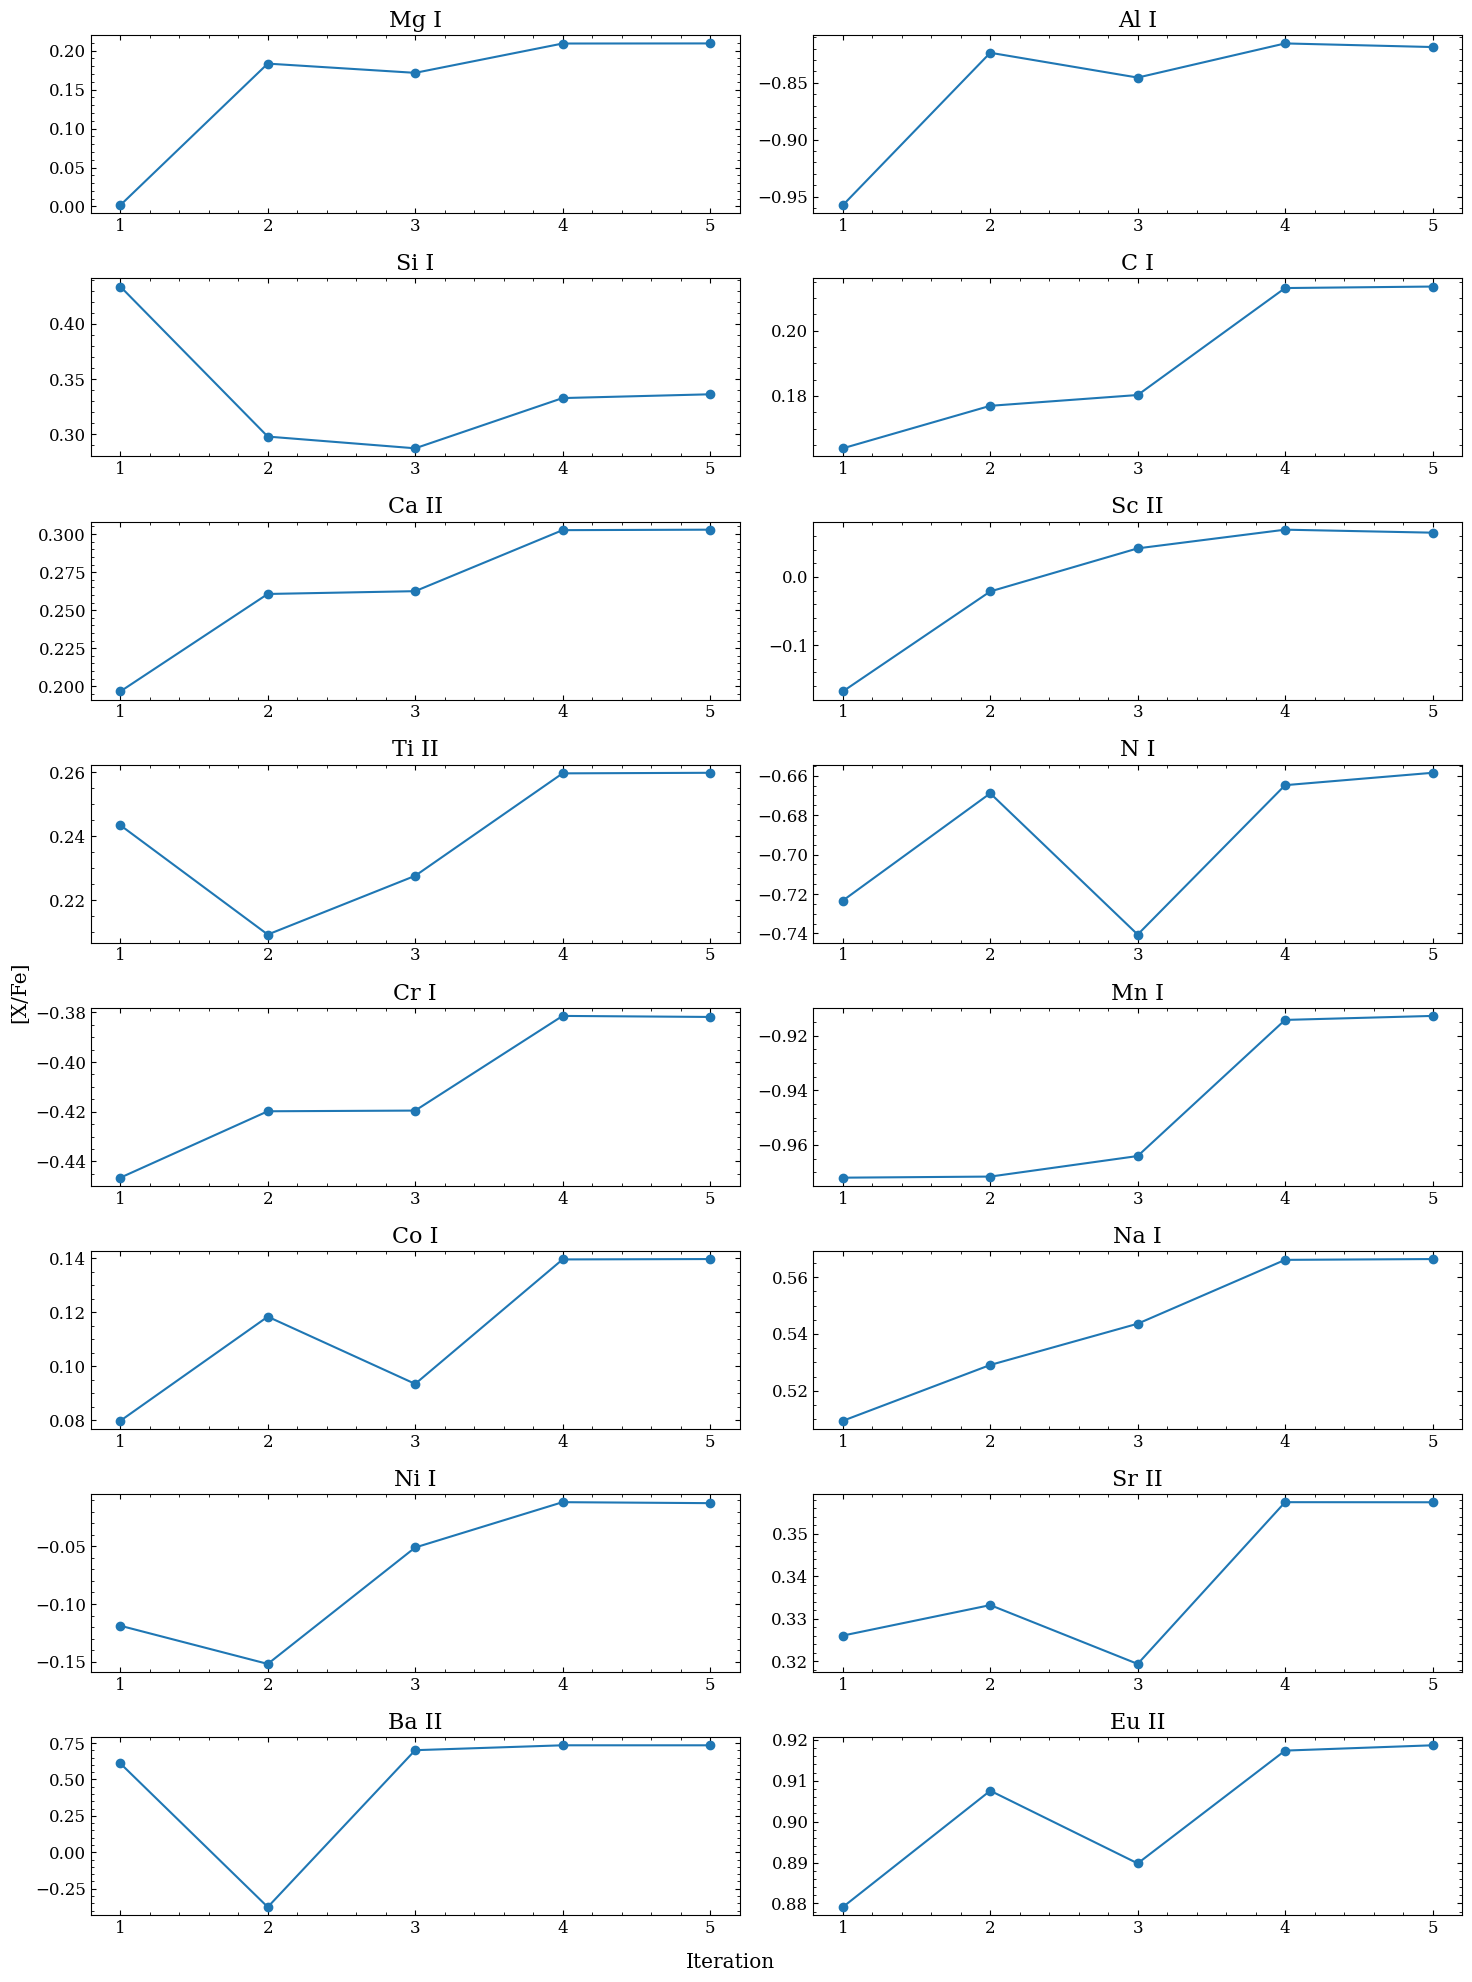

In [8]:
# Plotting the abundances for each iteration
fig, axs = plt.subplots(8, 2, figsize=[15,20], tight_layout=True)

# fig.subplots_adjust(wspace=0.25)
fig.supxlabel('Iteration')
fig.supylabel('[X/Fe]')

for ax, el in zip(axs.flat, els):
    el_abunds = it_abunds_df[it_abunds_df["element"] == el]
    ax.plot([1,2,3,4,5], [el_abunds["it1"].values[0], el_abunds["it2"].values[0], el_abunds["it3"].values[0], el_abunds["it4"].values[0], el_abunds["it5"].values[0]], marker='o')
    ax.set_title(el.replace("_", " "))
    ax.set_xticks([1,2,3,4,5])
    ax.set_xticklabels(['1', '2', '3', '4', '5'])
    
# plt.savefig("/data/misfit/benlowe/xshooter/p113/results/referee_comments/abund_iterations/" + star + "_abund_iterations.png")
# plt.close()